# Unterrichtsbeispiel
[&larr; Einführung](01_NUMPY.ipynb)

## Motivation

Um mit **NumPy** vertraut zu werden, wollen wir hier den Geschwindigkeitsverlauf eines Speed-Fallschirmspringers bestimmen. Der Fokus liegt hier nicht auf den physikalischen Zusammenhängen, sondern auf der Umsetzung der Berechnungen bzw. der verwendeten NumPy-Arrays als Datentypen.

<figure style="text-align:center; margin:1em auto;">
    <video controls="controls" muted src="img/Skydiver.mp4" width=100%>
    </video>
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Abb.: Speed Skydiver
        <a href="https://www.youtube.com/watch?v=IK3oH4jbwv0">[Quelle]</a>
    </figcaption>
</figure>

## Aufgabe

**Berechne den Geschwindigkeitsverlauf eines Speed-Fallschirmspringers für ca. 30 s nach Absprung.**

### a) Freier Fall ohne Luftwiderstand

Um an deinem Wissen aus der Physik (Kinematik) anzuknüpfen, wollen wir zuerst annehmen, dass kein Luftwiderstand wirkt, d. h. der **freie Fall ohne Luftwiderstand** vorliegt. Dann wirkt lediglich die Gewichtskraft $F_G = m \cdot g$, wobei $m$ die Masse des Fallschirmspringers und $g$ die Erdbeschleunigung (= 9.81 $\textsf{m/s}^\textsf{2}$) ist. Gemäss dem 2. NEWTON'schen Gesetz $F = m \cdot a$ ergibt sich in diesem Fall eine konstante Beschleunigung und es resultieren die Beziehungen, welche du aus der Physik (Kinematik) kennst.

Beschleunigung
$$ a = \frac{F_G}{m} = g = \text{const.} $$

Geschwindigkeit
$$ v = a \cdot t $$

In [4]:
import numpy as np

T = 30.0  # Zeitdauer [s]
dt = 0.01  # Zeitschrittweite [s]

g = 9.81  # Erdbeschl. [m/s^2]

t = np.arange(0, T, dt)  # Zeitarray [s]

v_ideal = g * t

### a) Freier Fall mit Luftwiderstand

Wird der Luftwiderstand berücksichtigt, wirkt neben der Gewichtskraft $F_G$ zusätzlich eine Reibungskraft $F_R$ (Luftwiderstand), die entgegen der Bewegungsrichtung wirkt. 

<figure style="text-align:center; margin:1em auto;">
    <img src="img/Fallschirm.png" width=60% />
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Abb.: Kräfte bei Fallschirmsprung
    </figcaption>
</figure>

Die Reibungskraft ist abhängig von der Luftdichte $\rho_{Luft}$, der Querschnittsfläche des fallenden Objektes $A$, des Widerstandskoeffizienten $c_d$ (*Drag*) sowie des Quadrates der Geschwindigkeit $v^2$. 

$$ F_R = \frac{1}{2} \cdot \rho_{Luft} \cdot A \cdot c_w \cdot v^2 $$

Da die Reibungskraft (Luftwiderstand) mit zunehmender Geschwindigkeit ansteigt, ist die Beschleunigung nicht mehr konstant, sondern nimmt mit der Zeit ab, bis irgendwann ein Kräftegleichgewicht herrscht und die Beschleunigung auf 0 sinkt. Mit der resultierenden Kraft ergibt sich gemäss NEWTON:

$$F_{Res} = F_G - F_R = m \cdot a$$

Lösen wir die obigen Beziehungen nach der Beschleunigung $a$ auf und setzen entsprechend ein, so erhalten wir:

$$a = \frac{F_G - F_R}{m} = g - \frac{\rho_{Luft} \cdot A \cdot c_w}{2 \cdot m} \cdot v^2$$

---

In [17]:
m = 85  # Gesamtgewicht Fallschirmspringer [kg]
rho_Luft = 1.2  # Dichte der Luft [kg/m^3]
A = 0.3  # Querschnittsfläche des Fallschirmspringers [m^2]
c_w = 0.295  # Widerstandsbeiwert [-]

k = 1/2 * rho_Luft * A * c_w

v_real = np.zeros_like(t)
a_real = np.zeros_like(t)
a_real[0] = g
for i in range(1,len(t)): # alternativ von 0 bis len(t)-1 und dann alle nachfolgenden Indices +1
    a_real[i] = g - k/m * v_real[i-1]**2
    v_real[i] = v_real[i-1] + a_real[i] * dt

# Das Verfahren wird explizites Euler-Verfahren (oder Euler-vorwärts-Verfahren) genannt.
# Dies ist ein Standardwerkzeug der numerischen Mathematik zum Lösen von Differentialgleichungen.

### c) Grafische Darstellung

Die Bibliothek für grafische Darstellungen (Matplotlib) werden wir in einem zukünftigen Unterrichtsblock genauer anschauen. Damit wir trotzdem eine Visualisierung der oben berechneten Geschwindigkeitsverläufe darstellen können, verwenden wir Matplotlib an dieser Stelle ohne näher darauf einzugehen

- Aktiviere die Plot-Zeile im untenstehenden Codeabschnitt
- Gehe jede Zeile durch und versuche diese nachzuvollziehen.

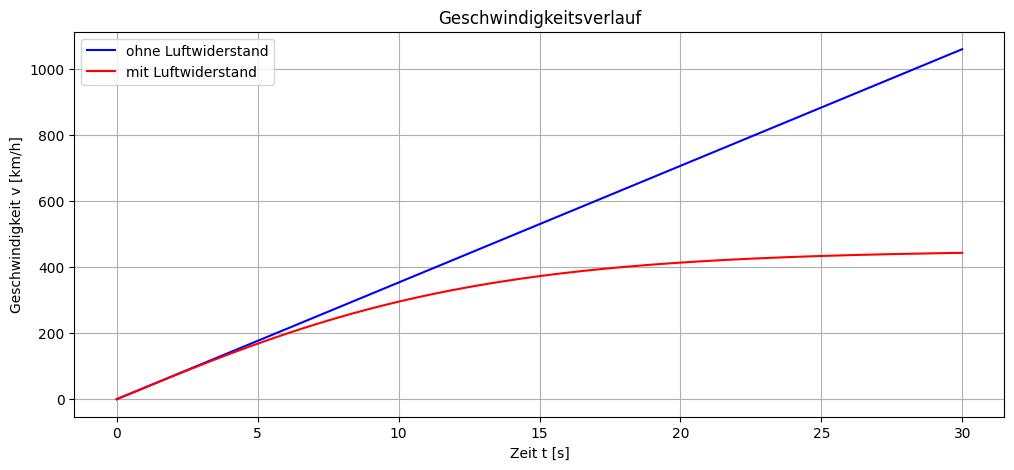

In [18]:
import matplotlib.pyplot as plt  # Importieren der Plotting-Library

plt.figure(figsize=(12,5))
plt.plot(t, v_ideal * 3.6, 'b', label='ohne Luftwiderstand')
plt.plot(t, v_real * 3.6, 'r', label='mit Luftwiderstand')
plt.xlabel("Zeit t [s]")
plt.ylabel("Geschwindigkeit v [km/h]")
plt.title("Geschwindigkeitsverlauf")
plt.grid()
plt.legend()
plt.show()

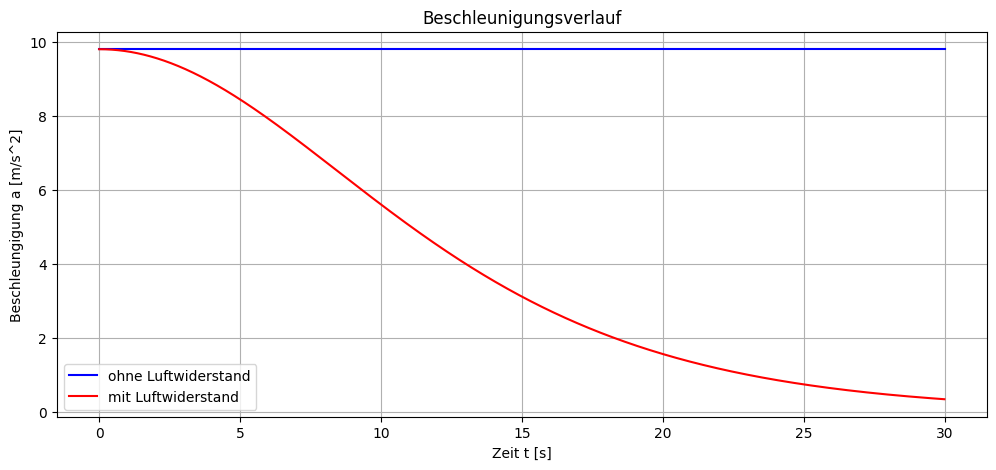

In [19]:
plt.figure(figsize=(12,5))
plt.plot([0, T], [g, g], 'b', label='ohne Luftwiderstand')
plt.plot(t, a_real, 'r', label='mit Luftwiderstand')
plt.xlabel("Zeit t [s]")
plt.ylabel("Beschleungigung a [m/s^2]")
plt.title("Beschleunigungsverlauf")
plt.grid()
plt.legend()
plt.show()